In [104]:
import numpy as np
import matplotlib.pyplot as plt
from cycler import cycler


rng = np.random.default_rng()

Questão 1

In [105]:

def randomwalklento(probabilidade, passos):
    
    x = [0]
    
    for i in  range(passos):
        
        r = rng.random()
        
        if r >= 1-probabilidade:
            x.append(x[-1] + 1)
        else:
            x.append(x[-1] - 1)
            
            
    return x


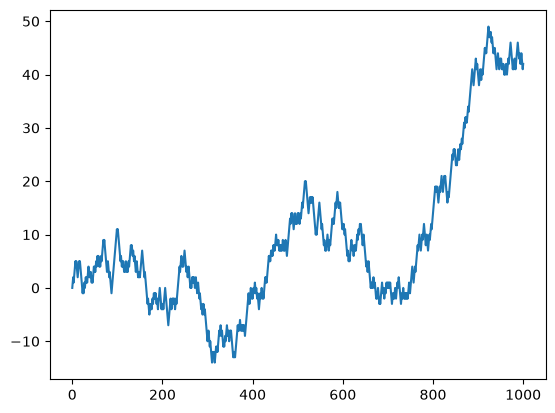

In [106]:
plt.plot(randomwalklento(0.53, 1000))
plt.show()


Questão 2

In [107]:

def randomwalkrapido(probabilidade, passos):
    
    passos = rng.choice(a =[1,-1], size= 100, replace= True, p = [probabilidade , 1-probabilidade])
    
    trajetoria = np.cumsum(passos)
    
    return trajetoria


In [108]:
traj =  randomwalkrapido(0.55 , 100)

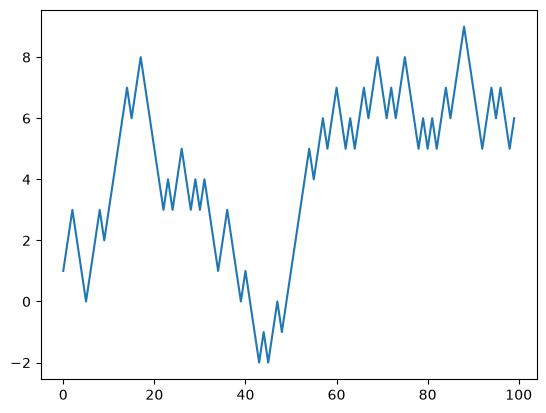

In [109]:
plt.plot(traj)
plt.show()


Questão 3

In [110]:

def randomwalkrapido(probabilidade, passos, bebados):

    traj = np.zeros(bebados)
    
    passos = rng.choice(a =[1,-1], size= [passos , bebados], replace= True, p = [probabilidade , 1-probabilidade])
    
    trajetoria = np.cumsum(passos, axis = 0)
    
    traj = np.vstack([traj, trajetoria])
    
    return traj


Questão 4

In [111]:

trajetoria1 = randomwalkrapido(0.62, 1000, 500)
trajetoria2 = randomwalkrapido(0.50, 1000 , 500)

tons_azul = ['#03045e', '#023e8a', '#0077b6', '#0096c7', '#00b4d8']
tons_rosa = ['#590d22', '#800f2f', '#a4133c', '#c9184a', '#ff4d6d']

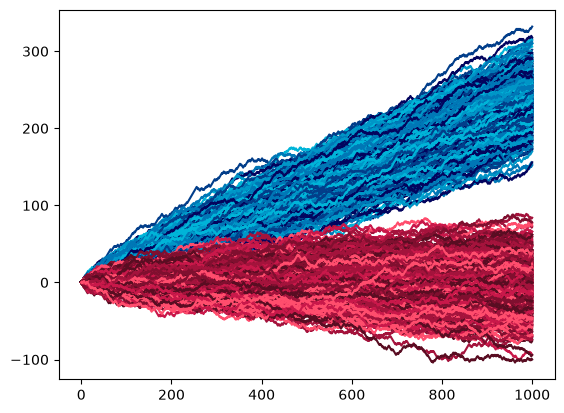

In [112]:
plt.gca().set_prop_cycle(cycler(color=tons_azul))
plt.plot(trajetoria1)
plt.gca().set_prop_cycle(cycler(color=tons_rosa))
plt.plot(trajetoria2)
plt.show()

Questão 5

In [113]:

def randomwalkrapido(probabilidade, passos, bebados):

    traj = np.zeros(bebados)
    
    passos = rng.choice(a =[1,-1], size= [passos , bebados], replace= True, p = [probabilidade , 1-probabilidade])
    
    trajetoria = np.cumsum(passos, axis = 0)
    
    traj = np.vstack([traj, trajetoria])
    
    media = np.mean(trajetoria, axis = 1,  keepdims = True)
 
    desviopadrao = np.std(trajetoria, axis = 1, dtype = 'float64', keepdims = True)
        
    return traj , media , desviopadrao


In [114]:
x1 , media1 , desviopadrao1 = randomwalkrapido(0.62, 1000, 500)
x2 , media2 , desviopadrao2 = randomwalkrapido(0.33, 1000, 500)

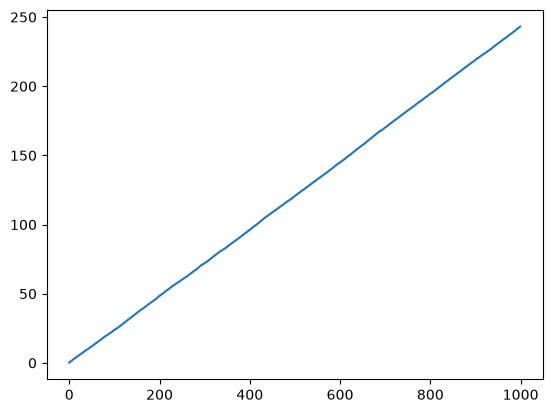

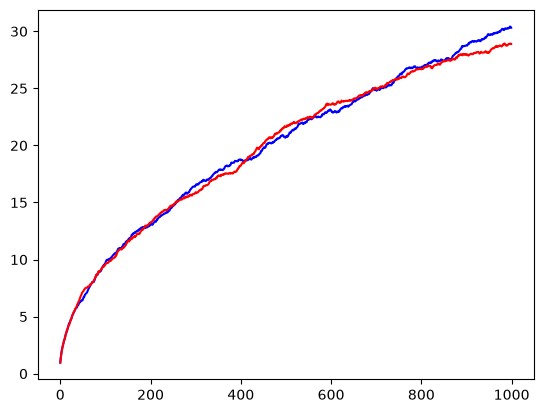

In [115]:
plt.plot(media1)
plt.show()

plt.plot(desviopadrao1, c = "blue")
plt.plot(desviopadrao2, c = "red")
plt.show()

Questão 6

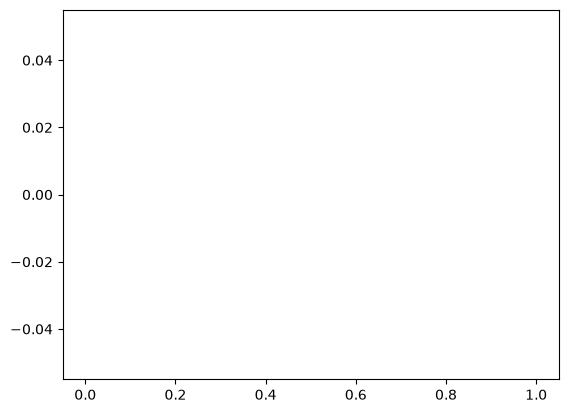

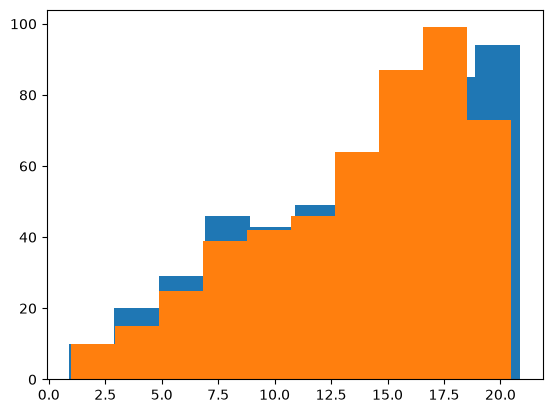

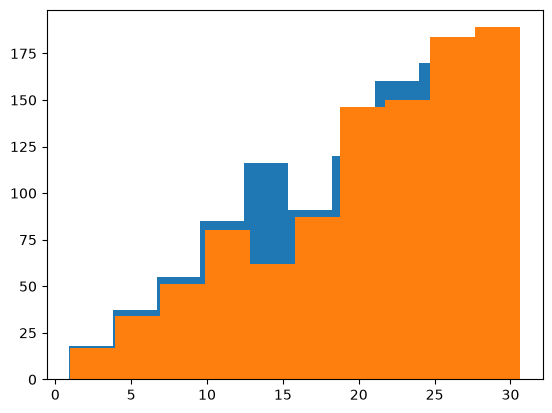

In [116]:
plt.hist(randomwalkrapido(0.71, 0, 500)[-1])
plt.hist(randomwalkrapido(0.38, 0, 500)[-1])
plt.show()

plt.hist(randomwalkrapido(0.71, 500, 500)[-1])
plt.hist(randomwalkrapido(0.38, 500, 500)[-1])
plt.show()

plt.hist(randomwalkrapido(0.71, 1000, 500)[-1])
plt.hist(randomwalkrapido(0.38, 1000, 500)[-1])
plt.show()

Questão 7

In [117]:
Elementos , elementos1 = np.histogram(x1 , bins = 10)
elementos , elementos2 = np.histogram(x2 , bins = 10)

mapa2d = Elementos[np.newaxis, :]
Mapa2d = elementos[np.newaxis, :]


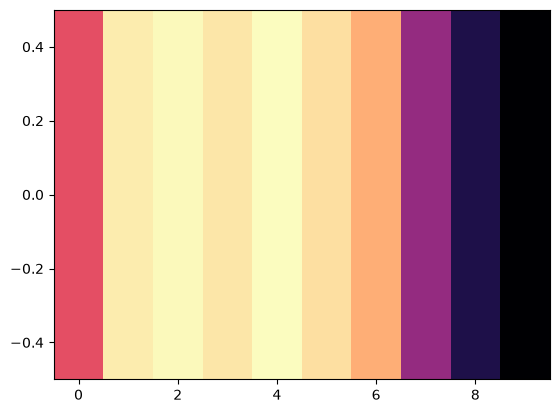

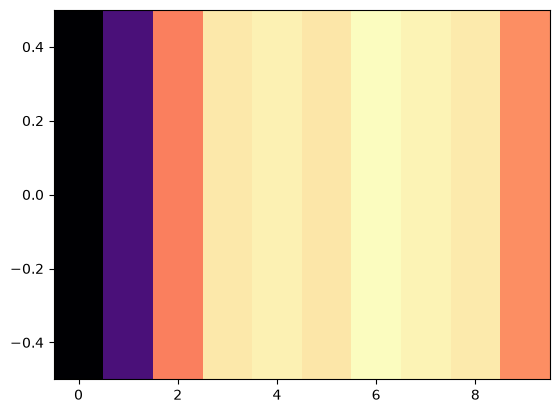

In [121]:

plt.imshow(mapa2d, aspect = 'auto' , origin = 'lower', cmap = 'magma')
plt.show()
plt.imshow(Mapa2d, aspect = 'auto' , origin = 'lower', cmap = 'magma')
plt.show()


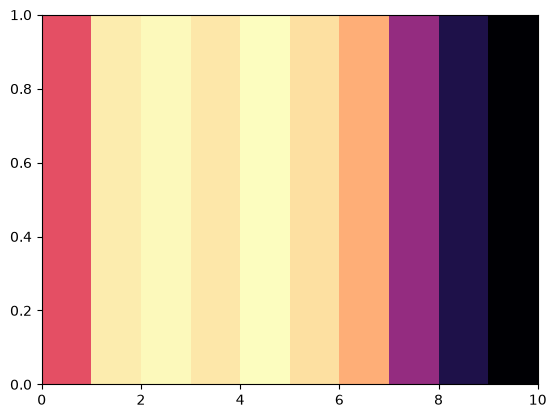

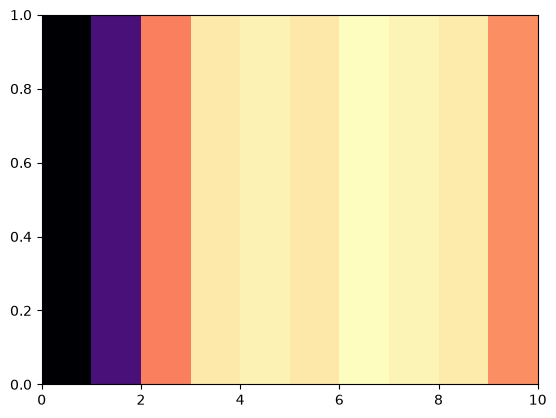

In [122]:

plt.pcolormesh(mapa2d, cmap = 'magma')
plt.show()
plt.pcolormesh(Mapa2d, cmap = 'magma')
plt.show()


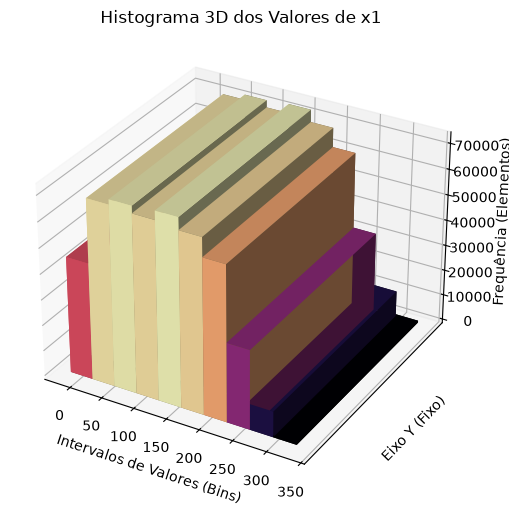

In [132]:
# 2. Configura a figura e o eixo para projeção 3D
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# 3. Define a posição de origem (base) de cada barra
x_pos = elementos1[:-1]          # Início de cada bin no eixo X
y_pos = np.zeros(10)         # Alinha todas as barras na posição 0 do eixo Y
z_pos = np.zeros(10)         # A base de todas as barras começa no nível zero do eixo Z

# 4. Define as dimensões (largura, profundidade e altura) de cada barra
dx = np.diff(elementos1)         # Largura de cada barra (tamanho do bin no eixo X)
dy = np.ones(10) * 0.5       # Profundidade da barra no eixo Y (valor estético fixo)
dz = Elementos               # Altura da barra no eixo Z (a frequência calculada pelo histograma)

# 5. Plota as barras 3D com um mapa de cores (magma) proporcional à altura
# Criamos uma escala de cores baseada na altura de cada barra
valores_normalizados = (dz - dz.min()) / (dz.max() - dz.min() + 1e-9)
cores = plt.cm.magma(valores_normalizados)

ax.bar3d(x_pos, y_pos, z_pos, dx, dy, dz, color=cores, zsort='average')

# Customização do gráfico 3D
ax.set_title('Histograma 3D dos Valores de x1')
ax.set_xlabel('Intervalos de Valores (Bins)')
ax.set_ylabel('Eixo Y (Fixo)')
ax.set_zlabel('Frequência (Elementos)')

# Remove as marcações do eixo Y já que ele só serve para dar profundidade
ax.set_yticks([])

plt.show()

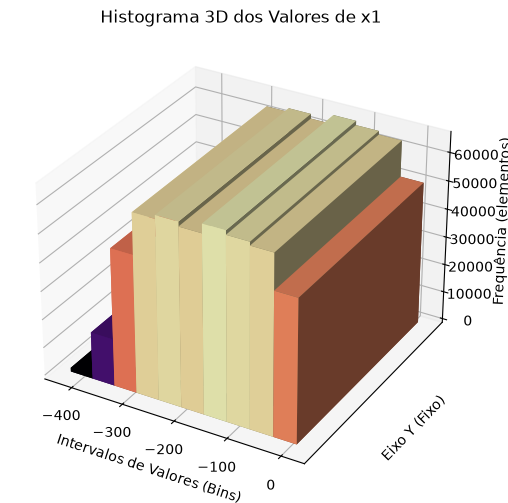

In [131]:
# 2. Configura a figura e o eixo para projeção 3D
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')

# 3. Define a posição de origem (base) de cada barra
x_pos = elementos2[:-1]          # Início de cada bin no eixo X
y_pos = np.zeros(10)         # Alinha todas as barras na posição 0 do eixo Y
z_pos = np.zeros(10)         # A base de todas as barras começa no nível zero do eixo Z

# 4. Define as dimensões (largura, profundidade e altura) de cada barra
dx = np.diff(elementos2)         # Largura de cada barra (tamanho do bin no eixo X)
dy = np.ones(10) * 0.5       # Profundidade da barra no eixo Y (valor estético fixo)
dz = elementos               # Altura da barra no eixo Z (a frequência calculada pelo histograma)

# 5. Plota as barras 3D com um mapa de cores (magma) proporcional à altura
# Criamos uma escala de cores baseada na altura de cada barra
valores_normalizados = (dz - dz.min()) / (dz.max() - dz.min() + 1e-9)
cores = plt.cm.magma(valores_normalizados)

ax.bar3d(x_pos, y_pos, z_pos, dx, dy, dz, color=cores, zsort='average')

# Customização do gráfico 3D
ax.set_title('Histograma 3D dos Valores de x1')
ax.set_xlabel('Intervalos de Valores (Bins)')
ax.set_ylabel('Eixo Y (Fixo)')
ax.set_zlabel('Frequência (elementos)')

# Remove as marcações do eixo Y já que ele só serve para dar profundidade
ax.set_yticks([])

plt.show()